
Training: 2 Layers
Accuracy: 42.8 %
Parameters: 141930
Training Time: 17.12 seconds

Training: 3 Layers
Accuracy: 40.0 %
Parameters: 52874
Training Time: 17.98 seconds

Training: 4 Layers
Accuracy: 35.0 %
Parameters: 37546
Training Time: 26.8 seconds

Training: 5x5 Filters
Accuracy: 43.7 %
Parameters: 370186
Training Time: 65.13 seconds

Training: Average Pool
Accuracy: 40.4 %
Parameters: 141930
Training Time: 12.87 seconds

Training: Batch Norm
Accuracy: 9.7 %
Parameters: 53258
Training Time: 30.72 seconds

Training: LR 0.01
Accuracy: 31.2 %
Parameters: 141930
Training Time: 15.71 seconds

Training: Batch 32
Accuracy: 45.2 %
Parameters: 141930
Training Time: 16.2 seconds

CNN COMPARISON RESULTS


,Configuration,Accuracy (%),Parameters,Training Time (sec)
0,2 Layers,42.8,141930,17.12
1,3 Layers,40.0,52874,17.98
2,4 Layers,35.0,37546,26.80
3,5x5 Filters,43.7,370186,65.13
4,Average Pool,40.4,141930,12.87
5,Batch Norm,9.7,53258,30.72
6,LR 0.01,31.2,141930,15.71
7,Batch 32,45.2,141930,16.20


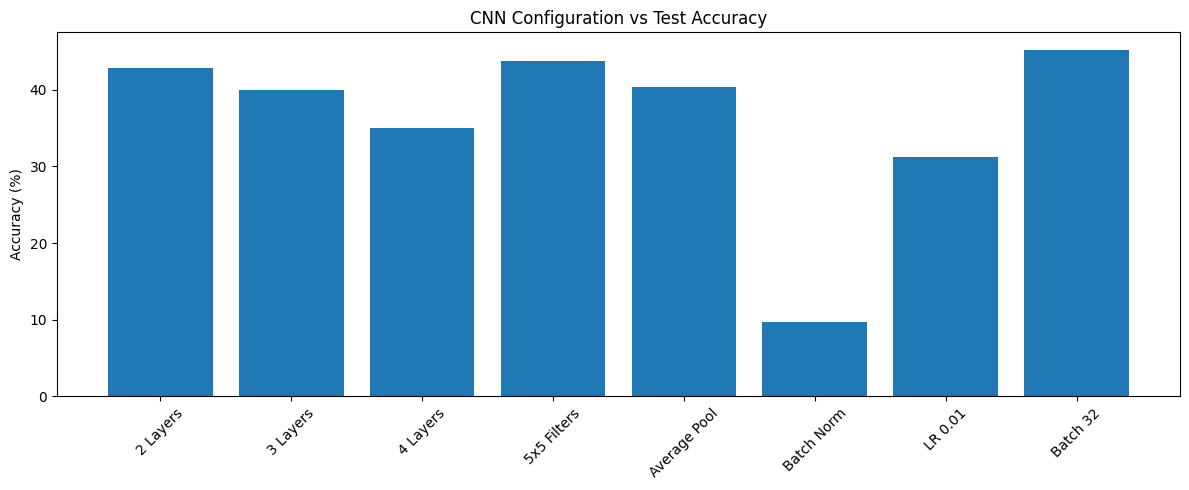

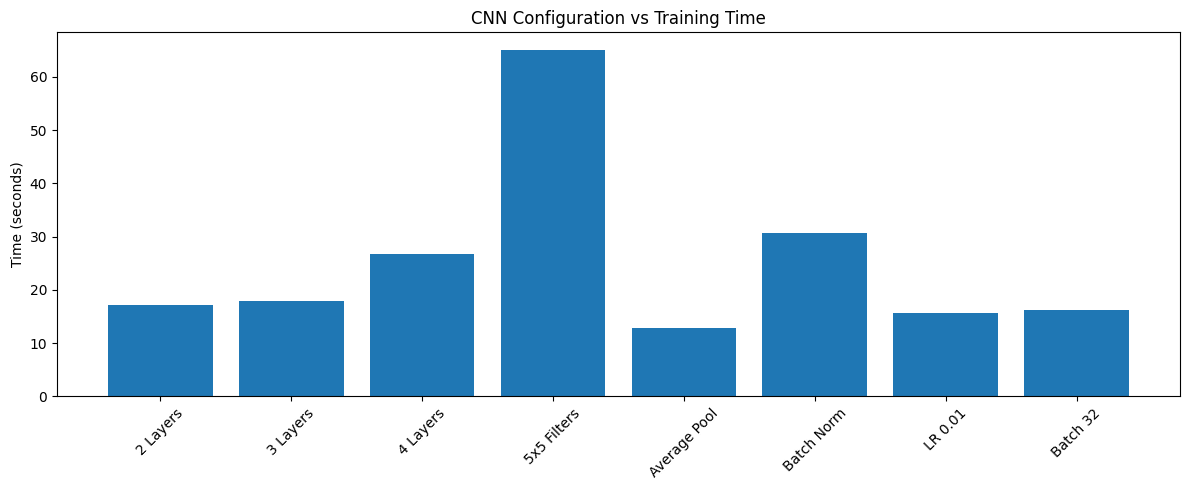

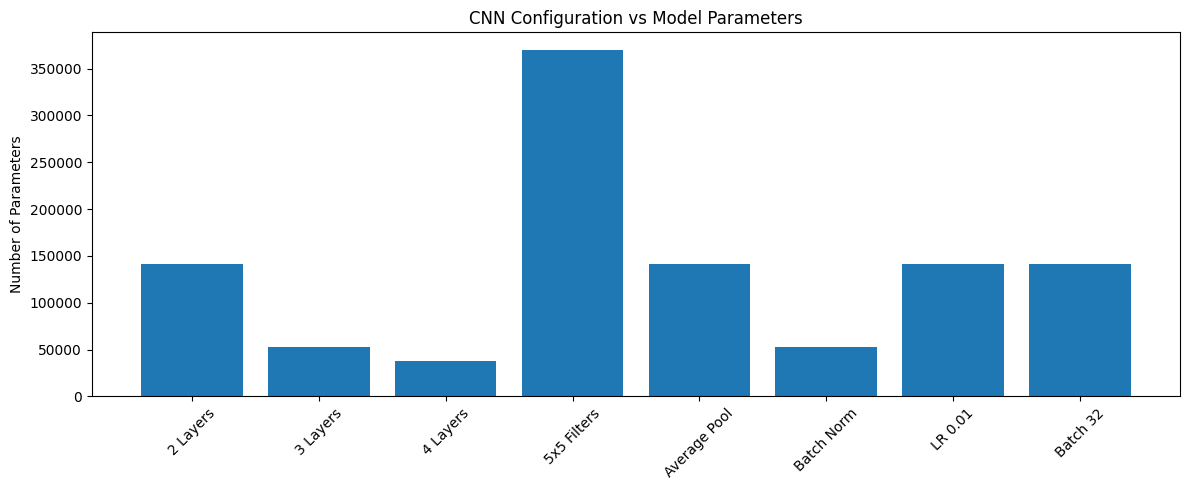

In [16]:
# EXPERIMENT 12: CNN ARCHITECTURE AND HYPERPARAMETER COMPARISON

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

from IPython.display import display
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10

# 1. Load dataset
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Use smaller subsets for faster experiment execution
x_train = x_train[:5000].astype("float32") / 255.0
y_train = y_train[:5000]

x_test = x_test[:1000].astype("float32") / 255.0
y_test = y_test[:1000]

# Split training data into training and validation
x_val = x_train[4000:]
y_val = y_train[4000:]

x_train = x_train[:4000]
y_train = y_train[:4000]

# 2. Define CNN model
def create_cnn(conv_layers, kernel_size, filters, pooling, batch_norm):

    model = models.Sequential()
    model.add(layers.Input(shape=(32, 32, 3)))

    for i in range(conv_layers):
        model.add(layers.Conv2D(filters, kernel_size,
                                padding="same", activation="relu"))

        if batch_norm:
            model.add(layers.BatchNormalization())

        if pooling == "max":
            model.add(layers.MaxPooling2D((2, 2)))
        else:
            model.add(layers.AveragePooling2D((2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation="relu"))
    model.add(layers.Dense(10, activation="softmax"))

    return model

# 3. Different configurations to compare
configs = [
    {"name": "2 Layers", "layers": 2, "kernel": 3,
     "filters": 32, "pool": "max", "bn": False,
     "lr": 0.001, "batch": 64},

    {"name": "3 Layers", "layers": 3, "kernel": 3,
     "filters": 32, "pool": "max", "bn": False,
     "lr": 0.001, "batch": 64},

    {"name": "4 Layers", "layers": 4, "kernel": 3,
     "filters": 32, "pool": "max", "bn": False,
     "lr": 0.001, "batch": 64},

    {"name": "5x5 Filters", "layers": 2, "kernel": 5,
     "filters": 64, "pool": "max", "bn": False,
     "lr": 0.001, "batch": 64},

    {"name": "Average Pool", "layers": 2, "kernel": 3,
     "filters": 32, "pool": "avg", "bn": False,
     "lr": 0.001, "batch": 64},

    {"name": "Batch Norm", "layers": 3, "kernel": 3,
     "filters": 32, "pool": "max", "bn": True,
     "lr": 0.001, "batch": 64},

    {"name": "LR 0.01", "layers": 2, "kernel": 3,
     "filters": 32, "pool": "max", "bn": False,
     "lr": 0.01, "batch": 64},

    {"name": "Batch 32", "layers": 2, "kernel": 3,
     "filters": 32, "pool": "max", "bn": False,
     "lr": 0.001, "batch": 32}
]

# 4. Train and evaluate all configurations
results = []

for config in configs:

    print("\nTraining:", config["name"])

    model = create_cnn(
        config["layers"],
        config["kernel"],
        config["filters"],
        config["pool"],
        config["bn"]
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=config["lr"]),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start = time.time()

    model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=3,
        batch_size=config["batch"],
        verbose=0
    )

    training_time = time.time() - start

    test_loss, test_accuracy = model.evaluate(
        x_test, y_test, verbose=0
    )

    results.append({
        "Configuration": config["name"],
        "Accuracy (%)": round(test_accuracy * 100, 2),
        "Parameters": model.count_params(),
        "Training Time (sec)": round(training_time, 2)
    })

    print("Accuracy:", round(test_accuracy * 100, 2), "%")
    print("Parameters:", model.count_params())
    print("Training Time:", round(training_time, 2), "seconds")

    del model

# 5. Display comparison table
results_df = pd.DataFrame(results)

print("\nCNN COMPARISON RESULTS")
display(results_df)

# 6. Plot accuracy comparison
plt.figure(figsize=(12, 5))
plt.bar(results_df["Configuration"], results_df["Accuracy (%)"])
plt.title("CNN Configuration vs Test Accuracy")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 7. Plot training time comparison
plt.figure(figsize=(12, 5))
plt.bar(results_df["Configuration"],
         results_df["Training Time (sec)"])
plt.title("CNN Configuration vs Training Time")
plt.ylabel("Time (seconds)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 8. Plot parameter comparison
plt.figure(figsize=(12, 5))
plt.bar(results_df["Configuration"], results_df["Parameters"])
plt.title("CNN Configuration vs Model Parameters")
plt.ylabel("Number of Parameters")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()